In [ ]:
import scrapy
from unidecode import unidecode
import json
import re
import csv
import nltk
from nltk.corpus import stopwords
import seaborn as sns
import umap.umap_ as umap
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import vstack
import numpy as np
import matplotlib.pyplot as plt
import subprocess
import os
import plotly.express as px

# Part 1: Crawler

In [52]:
class WikiSpider(scrapy.Spider):
    name = "wiki_ascii"
    allowed_domains = ["en.wikipedia.org"]
    start_urls = [
                "https://en.wikipedia.org/wiki/Bratislava",
                "https://en.wikipedia.org/wiki/French_Revolution",
                "https://en.wikipedia.org/wiki/James_Joyce"    
                ]

    custom_settings = {
        'DEPTH_PRIORITY': 1,
        'DEPTH_LIMIT' : 1,
        'FEEDS': {'wikipedia.json': {'format': 'json', 'encoding': 'utf8', 'ensure_ascii': False}}
    }


    def parse(self, response):
        title = response.xpath('//h1[@id="firstHeading"]//text()').getall()
        title = ''.join(title).strip()
        paragraphs = response.xpath('//div[@id="mw-content-text"]//p//text()').getall()
        text = " ".join(p.strip() for p in paragraphs if p.strip())

        title_ascii = unidecode(title)
        text_ascii = unidecode(text)

        yield {
            "url": unidecode(response.url),
            "title": title_ascii,
            "text": text_ascii,
        }
        depth = response.meta.get('depth', 0)
        if depth < 1:
            for href in response.xpath('//div[@id="bodyContent"]//a[@href]/@href').getall():
                if href.startswith("/wiki/") and ":" not in href:
                    next_page = response.urljoin(href)
                    yield scrapy.Request(next_page, callback=self.parse)


In [53]:
subprocess.run(['python', 'download_wiki.py'])

CompletedProcess(args=['python', 'download_wiki.py'], returncode=0)

My crawler uses BFS, there are 3 different articles, which are the foundation of my database: Bratislava, James Joyce and French revolution. So there are 3 big different areas that my database covers.

# Part 2: Lemmization

In [2]:
with open("wikipedia.json", "r", encoding="utf-8") as f:
    data = json.load(f)  

print(f"Number of articles: {len(data)}\n")

for i, article in enumerate(data[:3], start=1):
    print(f"Article {i}:")
    print("URL:", article.get("url"))
    print("Title:", article.get("title"))
    print("First 200 symbols:", article.get("text")[:200], "...\n")

Number of articles: 3405

Article 1:
URL: https://en.wikipedia.org/wiki/Bratislava
Title: Bratislava
First 200 symbols: Bratislava [ a ] (German: Pressburg ; Hungarian: Pozsony ) [ b ] is the capital and largest city of the Slovak Republic and the fourth largest of all cities on the river Danube . Officially, the popul ...

Article 2:
URL: https://en.wikipedia.org/wiki/French_Revolution
Title: French Revolution
First 200 symbols: The French Revolution [ a ] was a period of political and societal change in France that began with the Estates General of 1789 and ended with the Coup of 18 Brumaire on 9 November 1799. Many of the r ...

Article 3:
URL: https://en.wikipedia.org/wiki/James_Joyce
Title: James Joyce
First 200 symbols: James Augustine Aloysius Joyce (born James Augusta Joyce [ a ] ; 2 February 1882 - 13 January 1941) was an Irish novelist, poet, and literary critic . He contributed to the modernist movement and is r ...



In [3]:
def remove_brackets_content(text):
    text = re.sub(r'\(.*?\)', '', text)
    return re.sub(r'\[.*?\]', '', text)


def remove_templates(text):
    pattern = re.compile(r'\{\{.*?\}\}')
    while pattern.search(text):
        text = pattern.sub('', text)
    return text

def remove_section_titles(text):
    return re.sub(r'=+.*?=+', '', text)

def clean_wiki_text(text):
    text = remove_brackets_content(text)
    text = remove_templates(text)
    text = remove_section_titles(text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()
def filter_unique_articles(articles):
    seen_texts = set()
    unique_articles = []

    for article in articles:
        text = article.get('text', '')
        if text not in seen_texts:
            unique_articles.append(article)
            seen_texts.add(text)

    return unique_articles

def lemmatize_text(text):
    lemmatizer = nltk.WordNetLemmatizer()
    words = nltk.word_tokenize(text.lower())
    stop_words = set(stopwords.words('english'))
    filtered_words = [word for word in words if word.isalpha() and word not in stop_words]
    lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words]
    return ' '.join(lemmatized_words)

def processing(data):
    processed_data = []
    for article in data:
        url = article.get('url', '')
        title = article.get('title', '')
        text = article.get('text', '')

        text_processed = lemmatize_text(clean_wiki_text(text))

        processed_data.append({
            'url': url,
            'title': title,
            'text': text_processed
        })
    processed_data = filter_unique_articles(processed_data)
    return processed_data

processed_data = processing(data)
csv_columns = ['url', 'title', 'text']
with open('wiki_processed.csv', 'w', newline='', encoding='utf-8') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=csv_columns)
    writer.writeheader()
    for article in processed_data:
        writer.writerow(article)

In [4]:
for i, article in enumerate(processed_data[:3], start=1):
    print(f"Article {i}:")
    print("URL:", article.get("url"))
    print("Title:", article.get("title"))
    print("First 200 symbols:", article.get("text")[:200], "...\n")

Article 1:
URL: https://en.wikipedia.org/wiki/Bratislava
Title: Bratislava
First 200 symbols: bratislava capital largest city slovak republic fourth largest city river danube officially population city however source estimate daily number people moving around city based mobile phone sim card b ...

Article 2:
URL: https://en.wikipedia.org/wiki/French_Revolution
Title: French Revolution
First 200 symbols: french revolution period political societal change france began estate general ended coup brumaire november many revolution idea considered fundamental principle liberal democracy value remain central ...

Article 3:
URL: https://en.wikipedia.org/wiki/James_Joyce
Title: James Joyce
First 200 symbols: james augustine aloysius joyce irish novelist poet literary critic contributed modernist movement regarded among influential important writer century joyce novel ulysses landmark episode homer odyssey ...



# Part 3: Recommendation system

In [5]:
df = pd.read_csv('wiki_processed.csv', encoding='utf-8')
documents = df['text'].astype(str).tolist()

tfidf = TfidfVectorizer(use_idf=True, smooth_idf=False)
tfidf_matrix = tfidf.fit_transform(documents)
# df_matrix = pd.DataFrame(tfidf_matrix.toarray())
# df_matrix.to_csv("tfdif_matrix.csv", index=False, encoding='utf-8')

In [31]:
def recommend_similar_articles(visited_titles, top_n=10):
    visited_indices = []
    unknown_titles = []
    old_size = tfidf_matrix.shape[0]
    for title in visited_titles:
        if title not in df['title'].values:
            print(f"Article '{title}' not found in the database. Downloading article")
            url = f"https://en.wikipedia.org/wiki/{title}"
            unknown_titles.append(url)
        else:        
            idx = df.index[df['title'] == title][0]
            visited_indices.append(idx)
    
    if unknown_titles:
        unknown_titles = ','.join(unknown_titles)
        subprocess.run(['python', 'download_page.py', unknown_titles])
        with open("wikipedia_new.json", "r", encoding="utf-8") as f:
            data_new = json.load(f)     
        processed_data_new = processing(data_new)
        texts = [article['text'] for article in processed_data_new]
        upd_tfidf = tfidf.transform(texts)
        tfidf_matrix_combined = vstack([tfidf_matrix, upd_tfidf])
        os.remove('wikipedia_new.json')
        new_indices = list(range(old_size, old_size + len(texts)))
        visited_indices.extend(new_indices)
    else:
        tfidf_matrix_combined = tfidf_matrix
    
    user_profile = tfidf_matrix_combined[visited_indices].mean(axis=0)
    user_profile = np.asarray(user_profile)

    similarities = cosine_similarity(user_profile, tfidf_matrix_combined).flatten()
    results = pd.DataFrame({
        'title': df['title'],
        # 'url': df['url'],
        'similarity': similarities[:old_size]
    })

    results = results[~results['title'].isin(visited_titles)]
    recommendations = results.sort_values(by='similarity', ascending=False).head(top_n)
    return recommendations


In [33]:
visited_articles = [
    "James Joyce",
]

top_recommendations = recommend_similar_articles(visited_articles, top_n=10)
print("\nTop Recommended Articles:")
print(top_recommendations)



Top Recommended Articles:
                                        title  similarity
29                        Stephen James Joyce    0.704079
3150                    John Stanislaus Joyce    0.594857
2893                            Giacomo Joyce    0.577314
27                        Mary Gertrude Joyce    0.574600
3161                              Lucia Joyce    0.566552
3164                                Dubliners    0.555273
3162  A Portrait of the Artist as a Young Man    0.552404
5                James Joyce (disambiguation)    0.539818
26                 List of Ulysses characters    0.537337
3117                              John Conmee    0.503322


In [34]:
visited_articles = [
    "James Joyce",
    "Ulysses (novel)",
    "Bratislava"
]

top_recommendations = recommend_similar_articles(visited_articles, top_n=10)
print("\nTop Recommended Articles:")
print(top_recommendations)



Top Recommended Articles:
                                        title  similarity
2941                            Leopold Bloom    0.553823
29                        Stephen James Joyce    0.532700
3162  A Portrait of the Artist as a Young Man    0.498571
26                 List of Ulysses characters    0.481745
3150                    John Stanislaus Joyce    0.444871
3164                                Dubliners    0.437701
2893                            Giacomo Joyce    0.425299
3161                              Lucia Joyce    0.415034
27                        Mary Gertrude Joyce    0.412934
2530             James Joyce Tower and Museum    0.410973


In [ ]:
visited_articles = [
    "International Crimes Tribunal (Bangladesh)",
    "International Criminal Tribunal for the former Yugoslavia"
]

top_recommendations = recommend_similar_articles(visited_articles, top_n=10)
print("\nTop Recommended Articles:")
print(top_recommendations)

Article 'International Crimes Tribunal (Bangladesh)' not found in the database. Downloading article
Article 'International Criminal Tribunal for the former Yugoslavia' not found in the database. Downloading article

Top Recommended Articles:
                                  title  similarity
3238             Revolutionary Tribunal    0.400538
771   Antoine Quentin Fouquier-Tinville    0.246658
2560                         Show trial    0.244428
393                 French criminal law    0.213980
2770                         Jury trial    0.199735
396                       Law of France    0.193884
392                 Judiciary of France    0.183720
410                  Politics of France    0.181483
1883                       Human rights    0.175188
1463      Committee of General Security    0.156516


As you can see, everything works both for known and unknown articles

# Part 4: Graphs, statistics and explainability

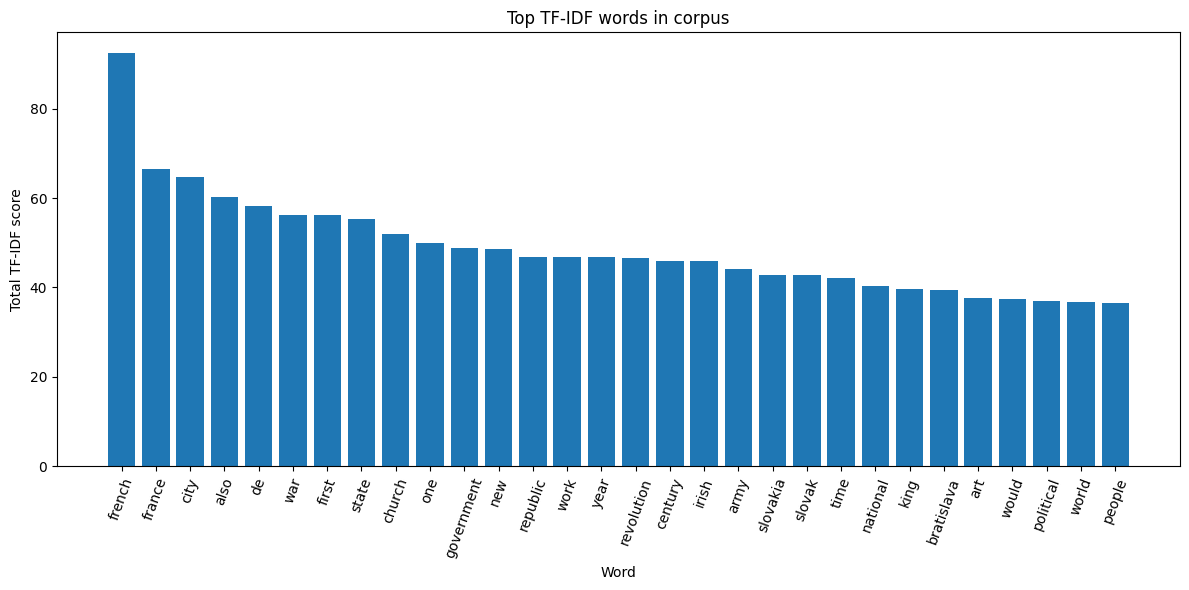

In [49]:
features = tfidf.get_feature_names_out()
word_scores = np.asarray(tfidf_matrix.sum(axis=0)).flatten()

top_indices = word_scores.argsort()[::-1][:30]

top_words = [features[i] for i in top_indices]
top_values = word_scores[top_indices]

plt.figure(figsize=(12,6))
plt.bar(top_words, top_values)
plt.xticks(rotation=70)
plt.title("Top TF-IDF words in corpus")
plt.xlabel("Word")
plt.ylabel("Total TF-IDF score")
plt.tight_layout()
plt.show()


C:\Users\konst\AppData\Local\Temp\ipykernel_16024\1800276051.py:17: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




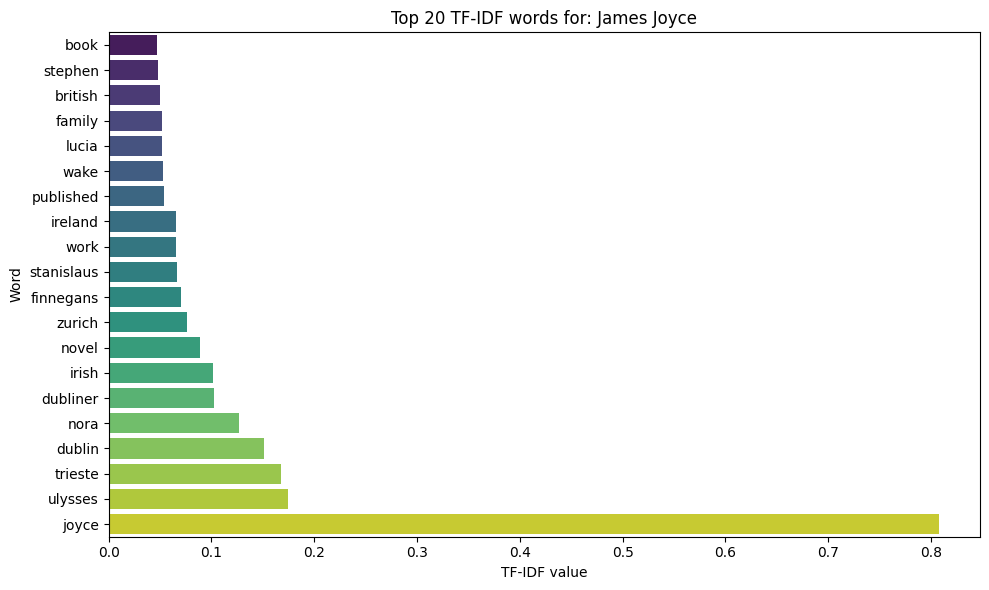

In [50]:
def plot_top_words_for_article(article_title, top_n=20):
    if article_title not in df['title'].values:
        print("Article not found.")
        return

    idx = df.index[df['title'] == article_title][0]
    vector = tfidf_matrix[idx].toarray().flatten()
    feature_names = tfidf.get_feature_names_out()

    top_idx = vector.argsort()[::-1][:top_n]
    words = feature_names[top_idx]
    scores = vector[top_idx]

    data = pd.DataFrame({"word": words, "tfidf": scores}).sort_values("tfidf")

    plt.figure(figsize=(10, 6))
    sns.barplot(data=data, x="tfidf", y="word", palette="viridis")
    plt.title(f"Top {top_n} TF-IDF words for: {article_title}")
    plt.xlabel("TF-IDF value")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()
plot_top_words_for_article("James Joyce")

In [54]:
n_neighbors=15
min_dist=0.1
reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, metric='cosine', random_state=42)

embedding = reducer.fit_transform(tfidf_matrix)
umap_df = pd.DataFrame({
    "x": embedding[:, 0],
    "y": embedding[:, 1],
    "title": df["title"]
})

fig = px.scatter(umap_df, x="x", y="y", hover_data=["title"])
fig.update_layout(template="plotly", title="UMAP projection map")
fig.show()

C:\Users\konst\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\utils\deprecation.py:132: FutureWarning:

'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.

C:\Users\konst\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\umap\umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



This is pretty interesting UMAP projection, as there is a right religious island, left isles of culture and main historico-geographical continent, with a small island of Swiss cities in the southeastern direction

In [55]:
from scipy.stats import entropy
def entropy_analysis(tfidf_matrix, df, top_n=20):
    entropies = []
    for i in range(tfidf_matrix.shape[0]):
        row = tfidf_matrix[i].toarray().flatten()
        row = row[row > 0]
        if len(row) > 0:
            ent = entropy(row)
        else:
            ent = 0
        entropies.append(ent)
    df_entropy = df.copy()
    df_entropy['entropy'] = entropies
    high_entropy = df_entropy.sort_values('entropy', ascending=False).head(top_n)
    low_entropy = df_entropy.sort_values('entropy', ascending=True).head(top_n)
    print("Articles with high entropy")
    print(high_entropy[['title', 'entropy']])
    print("\nArticles with low entropy")
    print(low_entropy[['title', 'entropy']])
    
    return high_entropy, low_entropy
 
high_ent, low_ent = entropy_analysis(tfidf_matrix, df)

Articles with high entropy
                                     title   entropy
224   Role of Christianity in civilization  7.803132
237        History of Western civilization  7.731427
3088                          Roman Empire  7.690077
266                            Reformation  7.650841
1614                                 Italy  7.649578
1827             Paris in the 18th century  7.635256
1500                                 Egypt  7.607510
3194                  Age of Enlightenment  7.592526
1461                             Modernism  7.563864
2623                                Poland  7.555732
3262                                France  7.546567
1340                         Joseph Conrad  7.543273
223                      Christian culture  7.541215
669            Counterculture of the 1960s  7.539364
3218                 French Third Republic  7.524064
2337                     Benjamin Franklin  7.514452
98                           Pope Pius XII  7.512657
1882               

This type of analysis can show us how complex the vocabulary of an article is. For example, lists and disambiguation are more technical pages, so their complexity is not so high, however in case of articles with complex theme, the entropy is increases. These are the articles about either complex cultural phenomena, or complex historical, geographical or political subject

Now, let's modify our primal function to see what are the words with maximal contribution in the decision to choose the next article

In [75]:
def get_recommendation_explanation(user_profile_vector, article_vector, feature_names, top_k=5):
    if hasattr(article_vector, "toarray"):
        article_vector = article_vector.toarray().flatten()
    contributions = np.multiply(user_profile_vector, article_vector)
    top_indices = contributions.argsort()[::-1][:top_k]
    explanation_parts = []
    for idx in top_indices:
        score = contributions[idx]
        if score > 0.001: 
            word = feature_names[idx]
            explanation_parts.append(f"{word} ({score:.3f})")
    return "; ".join(explanation_parts)

def recommend_similar_articles(visited_titles, top_n=10):
    visited_indices = []
    unknown_titles = []
    old_size = tfidf_matrix.shape[0]
    for title in visited_titles:
        if title not in df['title'].values:
            print(f"Article '{title}' not found. Downloading...")
            url = f"https://en.wikipedia.org/wiki/{title}"
            unknown_titles.append(url)
        else:        
            idx = df.index[df['title'] == title][0]
            visited_indices.append(idx)
    
    if unknown_titles:
        unknown_titles_str = ','.join(unknown_titles)
        subprocess.run(['python', 'download_page.py', unknown_titles_str])
        with open("wikipedia_new.json", "r", encoding="utf-8") as f:
            data_new = json.load(f)     
        processed_data_new = processing(data_new)
        texts = [article['text'] for article in processed_data_new]
        upd_tfidf = tfidf.transform(texts)
        tfidf_matrix_combined = vstack([tfidf_matrix, upd_tfidf])
        if os.path.exists('wikipedia_new.json'):
            os.remove('wikipedia_new.json')
        new_indices = list(range(old_size, old_size + len(texts)))
        visited_indices.extend(new_indices)
    else:
        tfidf_matrix_combined = tfidf_matrix
    
    
    user_profile_matrix = tfidf_matrix_combined[visited_indices].mean(axis=0)
    user_profile = np.asarray(user_profile_matrix)

    similarities = cosine_similarity(user_profile, tfidf_matrix_combined).flatten()
    results = pd.DataFrame({
        'title': df['title'],
        'similarity': similarities[:old_size],
        'original_index': range(old_size)
    })
    results = results[~results['title'].isin(visited_titles)]
    recommendations = results.sort_values(by='similarity', ascending=False).head(top_n).copy()
    
    feature_names = tfidf.get_feature_names_out()
    explanations = []
    user_profile_flat = user_profile.flatten()
    for _, row in recommendations.iterrows():
        article_idx = row['original_index']
        article_vector = tfidf_matrix_combined[article_idx]
        expl_str = get_recommendation_explanation(user_profile_flat, article_vector, feature_names, top_k=5)
        explanations.append(expl_str)
    recommendations['key_words'] = explanations
    
    return recommendations[['title', 'similarity', 'key_words']]


In [ ]:
visited_articles = [
    "James Joyce",
    "Ulysses (novel)",
    "Bratislava",
]
top_recs = recommend_similar_articles(visited_articles, top_n=10)
print(top_recs)

                                        title  similarity  \
2941                            Leopold Bloom    0.553823   
29                        Stephen James Joyce    0.532700   
3162  A Portrait of the Artist as a Young Man    0.498571   
26                 List of Ulysses characters    0.481745   
3150                    John Stanislaus Joyce    0.444871   
3164                                Dubliners    0.437701   
2893                            Giacomo Joyce    0.425299   
3161                              Lucia Joyce    0.415034   
27                        Mary Gertrude Joyce    0.412934   
2530             James Joyce Tower and Museum    0.410973   

                                              key_words  
2941  joyce (0.141); bloom (0.127); ulysses (0.026);...  
29    joyce (0.305); bloom (0.007); stephen (0.006);...  
3162  joyce (0.171); stephen (0.051); ulysses (0.014...  
26    joyce (0.195); ulysses (0.112); character (0.0...  
3150  joyce (0.228); dublin (0.011); u

: 

In [72]:
visited_articles = [
    "International Crimes Tribunal (Bangladesh)",
    "International Criminal Tribunal for the former Yugoslavia"
]
top_recs = recommend_similar_articles(visited_articles, top_n=10)
print(top_recs)

Article 'International Crimes Tribunal (Bangladesh)' not found. Downloading...
Article 'International Criminal Tribunal for the former Yugoslavia' not found. Downloading...
                                  title  similarity  \
3238             Revolutionary Tribunal    0.400538   
771   Antoine Quentin Fouquier-Tinville    0.246658   
2560                         Show trial    0.244428   
393                 French criminal law    0.213980   
2770                         Jury trial    0.199735   
396                       Law of France    0.193884   
392                 Judiciary of France    0.183720   
410                  Politics of France    0.181483   
1883                       Human rights    0.175188   
1463      Committee of General Security    0.156516   

                                              key_words  
3238  tribunal (0.207); trial (0.013); judge (0.011)...  
771   tribunal (0.086); trial (0.020); judge (0.008)...  
2560  trial (0.101); crime (0.006); sentenced (

# Conclusions

As we could see, our 2 crawlers are working fine, creating database and downloading articles, those are not in database. After cleaning and lemmization, recommendation system based on TF-IDF vectorization creates ranking for the next most interesting articles to see for the user. Distribution of articles can be seen on UMAP map, some interesting information about entropy of articles was obtained. In last part, the new function was introduced to explain what words are the most important for the algorithm to give the next recommendation